# 03 — Exploratory data analysis

## Goal of this step

Explore how churn relates to customer attributes. Reserve the test split before looking for modeling ideas; every chart below uses only training rows.

## Why this matters

EDA is like scouting a route before a trip. The test set is the final exam: reading its answers while preparing would give an unfair estimate of how well we learned.

Find the project root and import display tools. Reusable logic lives in src.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np  # noqa: F401
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
plt.rcParams["figure.figsize"] = (8, 4)


The fixed 80/20 stratified split is introduced now to protect the test set; notebook 05 explains it fully. No statistical preprocessor is fit.

training_rows          5616.000000
training_churn_rate       0.264423
dtype: float64

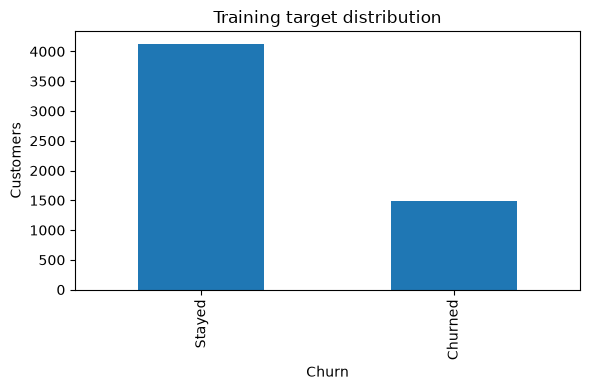

In [2]:
from src.split import training_frame
from src.eda import plot_target, plot_rates, plot_numeric, plot_outliers, plot_correlation, churn_rates, tenure_bucket, run_eda
df = training_frame()
display(pd.Series({'training_rows': len(df), 'training_churn_rate': df['Churn'].mean()}))
plot_target(df, show=True)

**Interpretation:** The training subset still contains a minority of churners, motivating recall and PR-AUC.

Plot churn rates and inspect counts: a rate from a tiny group is less reliable.

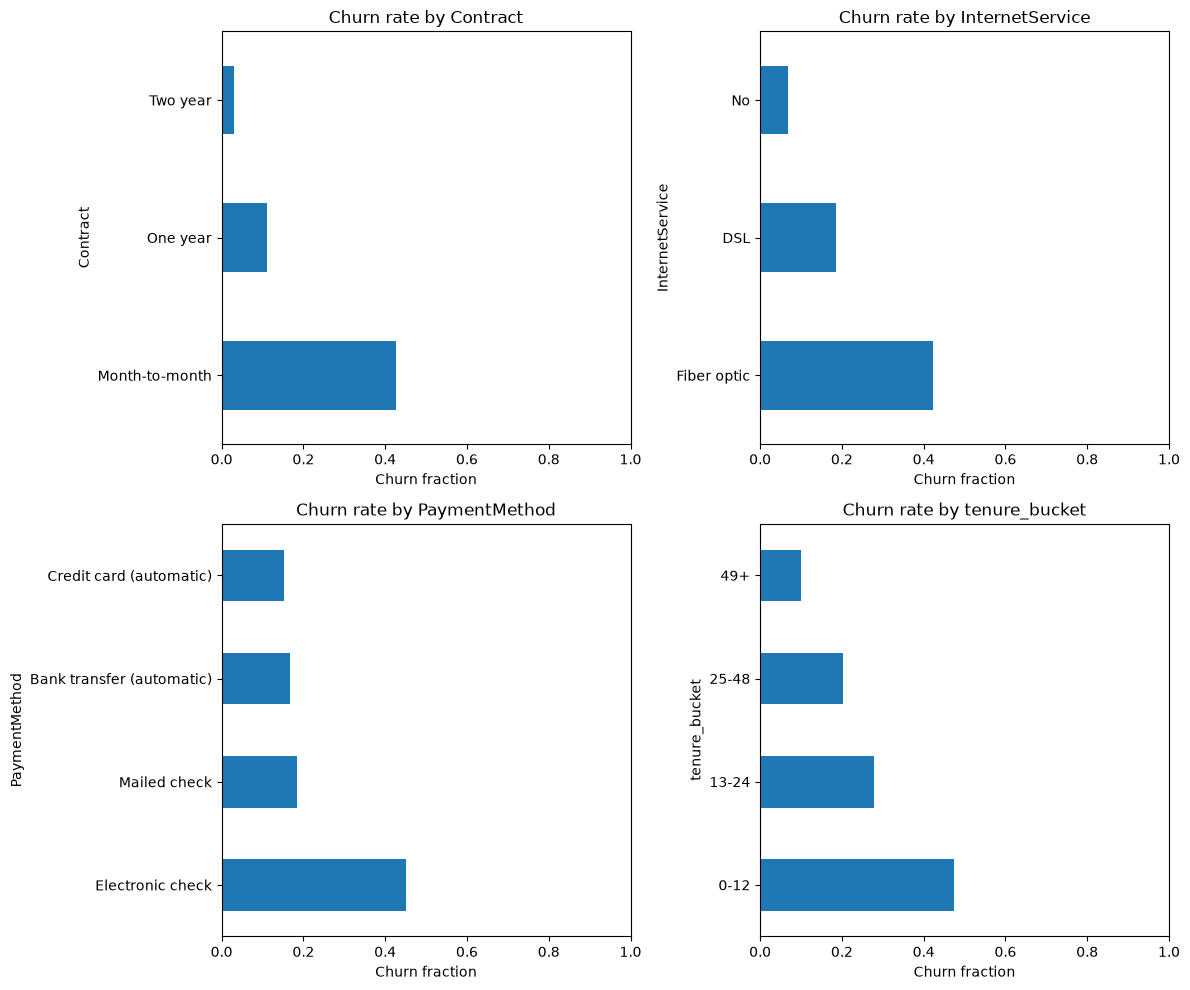

,customers,churn_rate
Contract,,
Month-to-month,3078,0.426576
One year,1182,0.111675
Two year,1356,0.029499


,customers,churn_rate
InternetService,,
Fiber optic,2469,0.423248
DSL,1933,0.185204
No,1214,0.067545


,customers,churn_rate
PaymentMethod,,
Electronic check,1905,0.451969
Mailed check,1269,0.184397
Bank transfer (automatic),1229,0.167616
Credit card (automatic),1213,0.151690


,customers,churn_rate
tenure_bucket,,
0-12,1728,0.473380
13-24,824,0.277913
25-48,1282,0.202028
49+,1782,0.100449


In [3]:
plot_rates(df, show=True)
for column in ['Contract', 'InternetService', 'PaymentMethod']:
    display(churn_rates(df, column))
display(churn_rates(df.assign(tenure_bucket=tenure_bucket(df['tenure'])), 'tenure_bucket'))

**Interpretation:** Contract, service, payment, and tenure groups have different observed churn rates; these are candidate predictors.

Separate numeric distributions by churn. Density normalization compares shapes even though the groups differ in size.

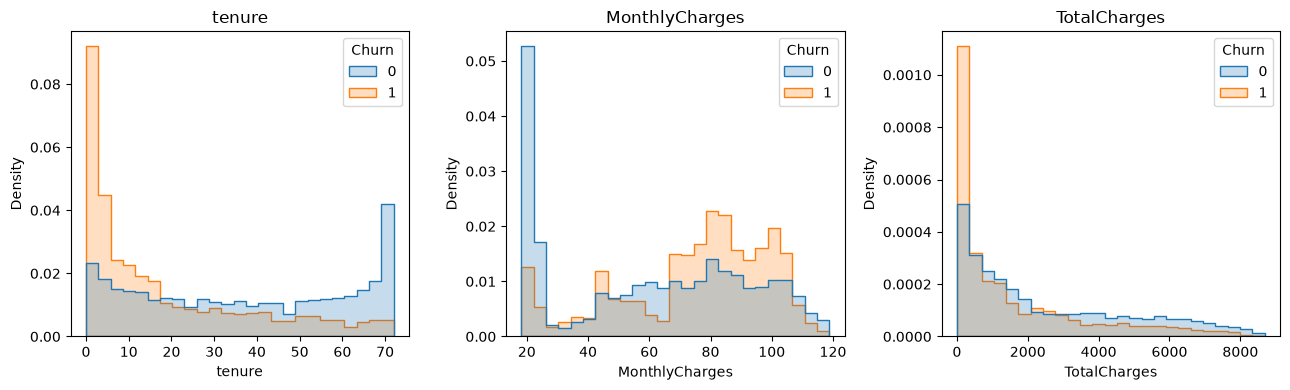

In [4]:
plot_numeric(df, show=True)

**Interpretation:** Tenure and charge distributions differ across outcomes; CV must establish whether these patterns generalize.

Inspect boxplots before deciding whether extreme values are data errors.

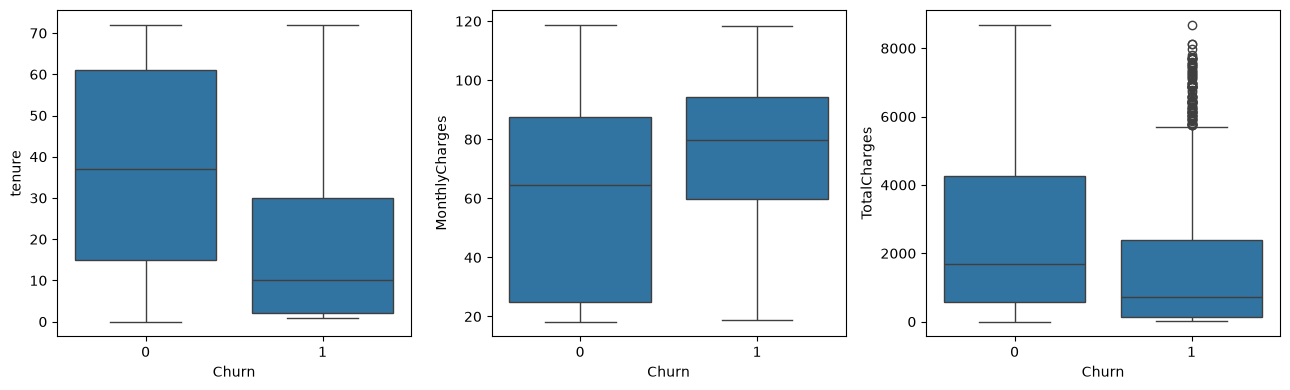

In [5]:
plot_outliers(df, show=True)

**Interpretation:** High bills can be legitimate; no automatic clipping or customer removal is justified.

Correlations reveal redundancy among numeric fields; they do not measure causality or categorical effects.

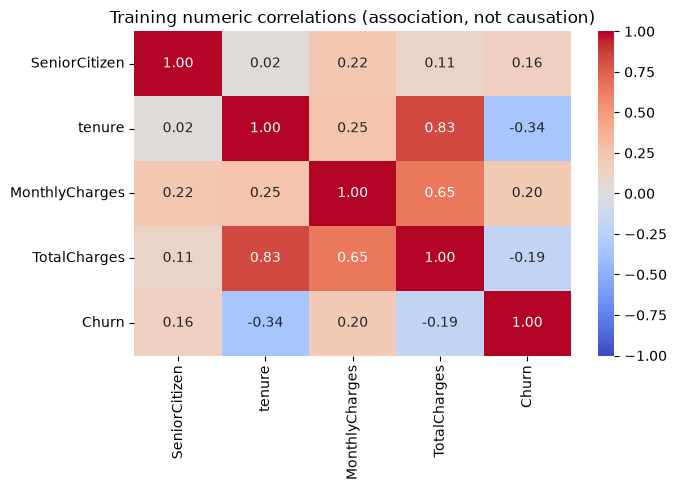

0    Contract: Month-to-month churns at 42.7% (n=30...
1    InternetService: Fiber optic churns at 42.3% (...
2    PaymentMethod: Electronic check churns at 45.2...
3    tenure_bucket: 0-12 churns at 47.3% (n=1728) v...
4    Median MonthlyCharges is 79.90 for churners an...
Name: Measured findings, dtype: str

In [6]:
plot_correlation(df, show=True)
notes = run_eda()
display(pd.Series(notes, name='Measured findings'))

**Interpretation:** TotalCharges and tenure are related; later charge ratios add another representation, with redundancy acknowledged.

## Common mistakes

- Exploring test labels before choosing features.
- Treating a group association as proof of causation.
- Deleting every point beyond a boxplot whisker.

## Key takeaways

- All modeling EDA uses training rows.
- Group counts give context to churn rates.
- EDA hypotheses must survive CV.

## Next step

04_feature_engineering.ipynb: encode business hypotheses with fold-safe preprocessing.

## Five data-backed findings

1. Contract: Month-to-month churns at 42.7% (n=3078) versus Two year at 2.9% (n=1356) -> encode contract duration; it may capture commitment; this is an association, not a causal effect.
2. InternetService: Fiber optic churns at 42.3% (n=2469) versus No at 6.8% (n=1214) -> encode service type and consider service-related interactions; this is an association, not a causal effect.
3. PaymentMethod: Electronic check churns at 45.2% (n=1905) versus Credit card (automatic) at 15.2% (n=1213) -> keep payment categories and test an autopay indicator; this is an association, not a causal effect.
4. tenure_bucket: 0-12 churns at 47.3% (n=1728) versus 49+ at 10.0% (n=1782) -> retain numeric tenure and test fixed tenure groups; this is an association, not a causal effect.
5. Median MonthlyCharges is 79.90 for churners and 64.50 for stayers -> test charge-related features without assuming price causes churn.